<a href="https://colab.research.google.com/github/komazawa-deep-learning/komazawa-deep-learning.github.io/blob/master/2026notebooks/2026_1112Visualization_first_layer_weights_on_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DNN の最下位層の特徴検出器 (結合係数) の視覚化

* date: 2026_1112
* filename: `2026_1112Visualization_first_layer_weights_on_CNN.ipynb`
* author: 浅川伸一
* license: MIT
* 元ファイル: `2024notebooks/2021_1029Visualization_the_visual_features_on_CNN.ipynb`

PyTorch (torchvision) 公式の訓練済みモデル 6 種について，入力に最も近い畳み込み層の結合係数 (重み) を画像として表示


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torchvision
from torchvision import models

print(f'torch: {torch.__version__}, torchvision: {torchvision.__version__}')

torch: 2.14.1+cpu, torchvision: 0.29.1+cpu


In [ ]:
try:
    import matplotlib_fontja
except ImportError:
    !pip install matplotlib-fontja
    import matplotlib_fontja

## ResNet18 の構造を確認する

In [ ]:
resnet = models.resnet18(weights='DEFAULT')
resnet.eval()
resnet

上の結果の冒頭は，次のように表示されます

* (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)

これは conv1 という名前の層で，

* 入力特徴数: 3 すなわち，入力データはカラー画像なので，赤，緑，青の光の 3 原色のそれぞれを表した数値となっています
* 出力特徴数: 64
* カーネルサイズ: (7, 7) 7 画素 X 7 画素のカーネル幅を持つ畳み込み演算が行われることを示しています
* ストライド: (2, 2) 縦と横とも 2 画素おきにずらしてカーネルが移動することを意味しています。
* パディング: (3, 3) 上下左右に入力画像の周辺に 3 画素分だけ架空の入力領域を確保していることを表します

torch.Size([64, 3, 7, 7])
min=-0.843, max=1.016, mean=0.000


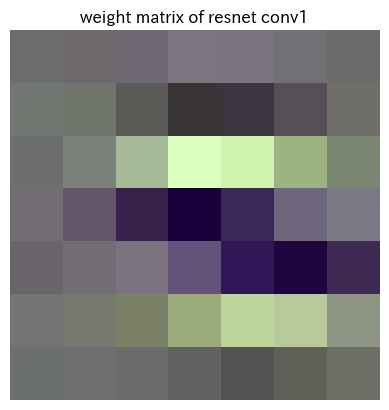

In [14]:
w = resnet.conv1.weight.detach()
# torch.Size([64, 3, 7, 7]) = [出力特徴数, 入力特徴数 (RGB), 縦, 横]
print(w.size())
print(f'min={w.min():.3f}, max={w.max():.3f}, mean={w.mean():.3f}')

w0 = w[0]; w0 = (w0 - w0.min()) / (w0.max() - w0.min())
plt.imshow(w0.permute(1, 2, 0).numpy())
plt.title('weight matrix of resnet conv1')
plt.axis(False)
plt.show()

## 表示用の関数

`torchvision.utils.make_grid` で全フィルタを格子状に並べる。
`normalize=True, scale_each=True` により，フィルタごとに最小値〜最大値を [0,1] に変換。

In [6]:
def show_filters(weight, title=None, nrow=8, figsize=(5, 5)):
    """畳み込み層の結合係数 [出力, 3, 縦, 横] を RGB 画像として格子状に表示する"""
    weight = weight.detach().cpu()
    assert weight.dim() == 4 and weight.size(1) == 3, f'入力 3 チャンネルの畳み込み層が必要: {tuple(weight.shape)}'
    grid = torchvision.utils.make_grid(weight, nrow=nrow, normalize=True, scale_each=True, padding=1, pad_value=1.0)
    plt.figure(figsize=figsize)
    plt.axis('off')
    plt.imshow(grid.permute(1, 2, 0).numpy(), interpolation='nearest')
    if title is not None:
        plt.title(f'{title}  {tuple(weight.shape)}')
    plt.show()

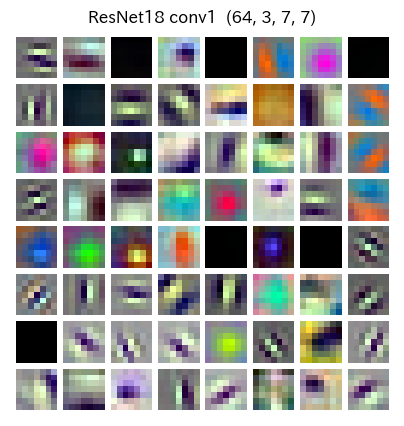

In [16]:
# ResNet18
show_filters(resnet.conv1.weight, title='ResNet18 conv1')

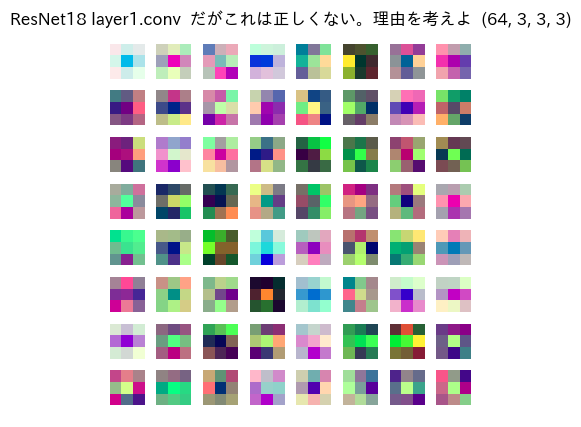

torch.Size([64, 3, 7, 7])


In [17]:
show_filters(resnet.layer1[0].conv1.weight[:,:3,:,:], title='ResNet18 layer1.conv  だがこれは正しくない。理由を考えよ')
print(resnet.conv1.weight.size())

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:02<00:00, 106MB/s] 


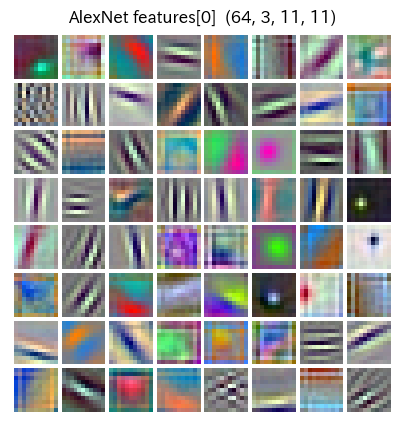

In [18]:
# AlexNet
net = models.alexnet(weights='DEFAULT')
show_filters(net.features[0].weight, title='AlexNet features[0]')

Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:00<00:00, 124MB/s] 


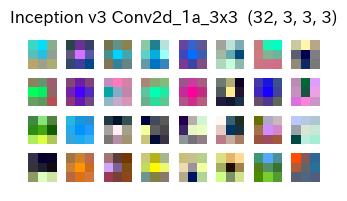

In [19]:
# Inception v3
net = models.inception_v3(weights='DEFAULT')
show_filters(net.Conv2d_1a_3x3.conv.weight, title='Inception v3 Conv2d_1a_3x3', figsize=(4, 4))

Downloading: "https://download.pytorch.org/models/vgg11-8a719046.pth" to /root/.cache/torch/hub/checkpoints/vgg11-8a719046.pth


100%|██████████| 507M/507M [00:03<00:00, 157MB/s]


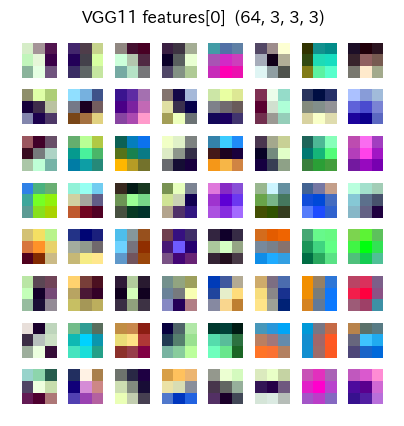

In [20]:
# VGG11
net = models.vgg11(weights='DEFAULT')
show_filters(net.features[0].weight, title='VGG11 features[0]')

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 98.7MB/s]


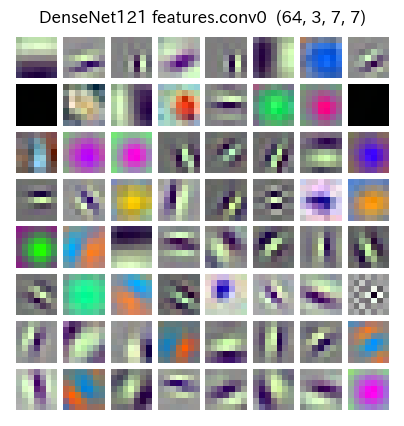

In [21]:
# DenseNet121
net = models.densenet121(weights='DEFAULT')
show_filters(net.features.conv0.weight, title='DenseNet121 features.conv0')

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 73.4MB/s]


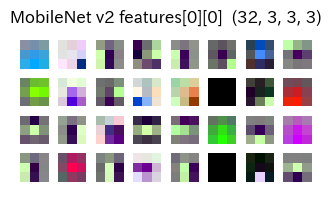

In [22]:
# MobileNet v2
net = models.mobilenet_v2(weights='DEFAULT')
show_filters(net.features[0][0].weight, title='MobileNet v2 features[0][0]', figsize=(4, 4))

### 読み取りの注意
* ResNet18 や DenseNet121 に見られる真っ黒のフィルタは，結合係数がほぼ 0 の「使われていない」フィルタです (表示の不具合ではありません)。
* Inception v3, VGG11, MobileNet v2 は 3×3 のカーネルなので，AlexNet (11×11) や ResNet (7×7) のような方位選択性 (ガボールフィルタ様の縞模様) は 1 層目からは読み取りにくくなります。

## 補足: 最初の畳み込み層を自動で探す

モデルごとに層の名前が異なるため，`named_modules()` で最初の `Conv2d` を探す関数を用意しておくと，他のモデルにも流用できます。

In [23]:
def first_conv(model):
    for name, m in model.named_modules():
        if isinstance(m, torch.nn.Conv2d):
            return name, m
    raise ValueError('Conv2d が見つかりません')

for arch in ['resnet18', 'alexnet', 'inception_v3', 'vgg11', 'densenet121', 'mobilenet_v2']:
    net = models.get_model(arch, weights='DEFAULT')
    name, conv = first_conv(net)
    print(f'{arch:14s} {name:24s} {tuple(conv.weight.shape)}')

resnet18       conv1                    (64, 3, 7, 7)
alexnet        features.0               (64, 3, 11, 11)
inception_v3   Conv2d_1a_3x3.conv       (32, 3, 3, 3)
vgg11          features.0               (64, 3, 3, 3)
densenet121    features.conv0           (64, 3, 7, 7)
mobilenet_v2   features.0.0             (32, 3, 3, 3)


## 第 2 層以降の結合係数の可視化

第 2 層以降の生の重みを並べても、ほとんど何も読み取れない。
以下のような手法が考えられる：

### A. 線形近似で画素空間に投影

- 考え方：ReLU を恒等写像に、MaxPool を AvgPool に置き換えると、ネットワークは線形になる。その状態で、ある層の各チャンネルの中心ユニットを入力画像で微分すると、画素空間での実効的な結合係数が RGB 画像として得られる。Distill の "Visualizing Weights"（Voss ら, 2021）にある expanded weights と同じ発想。
- 利点：入力画像を必要とせず、重みだけで計算できる。
- 結果：色の反対色の受容野や方位選択的なエッジが読み取れる。
- 欠点：
  - 非線形性を無視しているので、層が深くなるほど実際のユニットの振る舞いとずれる。conv3 より先では信用しにくい。
  - AlexNet ではストライド4が原因の格子状のノイズが出る。
  - ResNet の layer1 は残差接続を含むので、conv1 の成分が混ざって見える。

### B. 活性最大化（feature visualization）
- 考え方：ノイズ画像から始めて、あるチャンネルの出力が最大になるように入力画像を最適化する（Erhan ら 2009、Olah ら 2017 Distill）。
- 利点：学習データを必要としない。非線形性をそのまま扱えるので、深い層を見るにはこれが標準的な方法になる。
- 欠点：
  - 結果が正則化（ジッター、周波数空間でのパラメータ化など）に強く左右される。「そのユニットが好む画像」と言い切れるものではない。

### C. 生の重み＋入力チャンネルの見た目を組み合わせる（Circuits 方式）

- 考え方：各出力チャンネルについて、カーネルの L2 ノルムが大きい入力チャンネルを上位 k 個選ぶ。それらの入力チャンネルの見た目（第1層ならそのフィルタ画像、深い層なら B の結果）と並べて表示する（Olah ら 2020 "Zoom In"）。
- 利点：「どの特徴から何を組み立てているか」という配線そのものが見える。
- 欠点：図が複雑になり、1チャンネルずつしか見られない。

# Reference

* Erhan+(2009): Erhan, D., Bengio, Y., Courville, A., & Vincent, P. (2009). Visualizing Higher-Layer Features of a Deep Network (Technical Report 1341). Département d’Informatique et Recherche Opérationnelle, Université de Montréal.

* Olah+(2017): Olah, C., Mordvintsev, A., & Schubert, L. (2017). Feature Visualization. Distill, 2(11). https://doi.org/10.23915/distill.00007


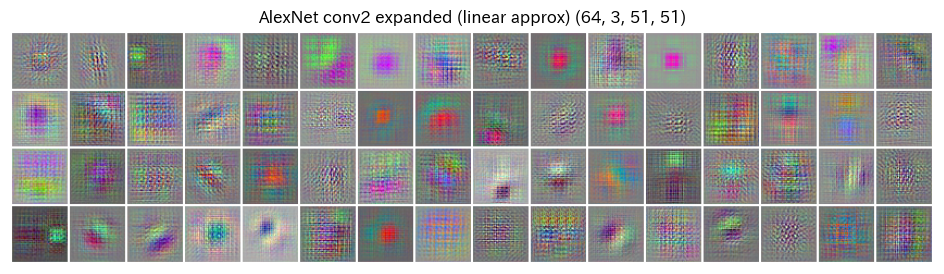

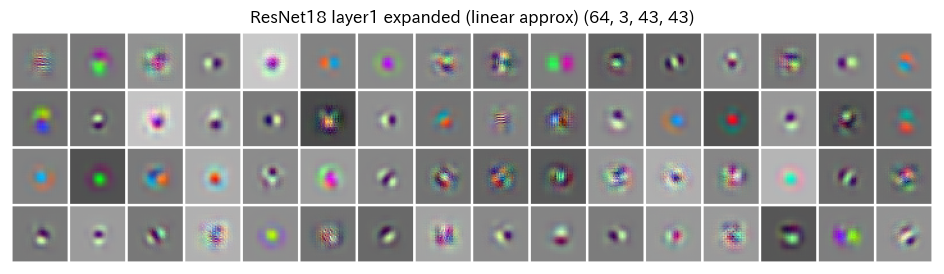

In [26]:
import copy
import torch, torch.nn as nn, torchvision
import matplotlib.pyplot as plt
from torchvision import models


def linearize(model):
    """ReLU を恒等写像, MaxPool を AvgPool に置き換えた線形近似モデルを返す (元のモデルは変更しない)"""
    m = copy.deepcopy(model).eval()
    for mod in list(m.modules()):
        for cname, child in list(mod.named_children()):
            if isinstance(child, (nn.ReLU, nn.ReLU6)):
                setattr(mod, cname, nn.Identity())
            elif isinstance(child, nn.MaxPool2d):
                setattr(mod, cname, nn.AvgPool2d(child.kernel_size, child.stride, child.padding,
                                                 ceil_mode=child.ceil_mode))
    return m


def expanded_weights(f, n_ch, size=127):
    """各チャンネルの中心ユニットを入力画像で微分し, 画素空間での実効的な結合係数を返す.

    f    : 画像 [N,3,H,W] -> 特徴マップ [N,C,h,w] の (線形化済み) 関数
    n_ch : 先頭から何チャンネル分を計算するか
    size : 入力画像の一辺. 受容野より十分大きくとる
    戻り値: [n_ch, 3, rf, rf]. 勾配が非零の領域 (= 受容野) で切り出したもの
    """
    # n_ch 枚の画像をまとめて流し, 画像 k ではチャンネル k の中心ユニットだけを取り出す.
    # 画像どうしは独立なので, 合計を 1 回 backward すれば各画像の勾配が個別に得られる.
    x = torch.zeros(n_ch, 3, size, size, requires_grad=True)
    y = f(x)
    cy, cx = y.shape[2] // 2, y.shape[3] // 2
    k = torch.arange(n_ch)
    y[k, k, cy, cx].sum().backward()
    grads = x.grad                                   # [n_ch, 3, size, size]

    support = grads.abs().sum(dim=(0, 1)) > 0        # どれかのチャンネルで勾配が非零の画素
    ys, xs = support.nonzero(as_tuple=True)
    return grads[:, :, ys.min():ys.max() + 1, xs.min():xs.max() + 1]


def show(w, title, fn=None, nrow=16):
    """フィルタを格子状に表示する. fn を与えればファイルにも保存する"""
    grid = torchvision.utils.make_grid(w, nrow=nrow, normalize=True, scale_each=True,
                                      padding=2, pad_value=1.0)
    fig = plt.figure(figsize=(12, 12 * grid.shape[1] / grid.shape[2]))
    plt.axis('off')
    plt.imshow(grid.permute(1, 2, 0).numpy())
    plt.title(f'{title} {tuple(w.shape)}')
    if fn is not None:
        fig.savefig(fn, dpi=90, bbox_inches='tight')
    plt.show()


lin_alex = linearize(models.alexnet(weights='DEFAULT'))
w2 = expanded_weights(lin_alex.features[:4], 64)      # conv1, relu, pool, conv2
show(w2, 'AlexNet conv2 expanded (linear approx)', 'alex_conv2.png')

lin_resnet = linearize(models.resnet18(weights='DEFAULT'))
f = nn.Sequential(lin_resnet.conv1, lin_resnet.bn1, lin_resnet.relu, lin_resnet.maxpool, lin_resnet.layer1)
w = expanded_weights(f, 64)
show(w, 'ResNet18 layer1 expanded (linear approx)', 'res_layer1.png')


In [27]:
lin_alex

AlexNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
    (1): Identity()
    (2): AvgPool2d(kernel_size=3, stride=2, padding=0)
    (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): Identity()
    (5): AvgPool2d(kernel_size=3, stride=2, padding=0)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): Identity()
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): Identity()
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): Identity()
    (12): AvgPool2d(kernel_size=3, stride=2, padding=0)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(6, 6))
  (classifier): Sequential(
    (0): Dropout(p=0.5, inplace=False)
    (1): Linear(in_features=9216, out_features=4096, bias=True)
    (2): Identity()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=4096, out_features=4096, bias=True)
    (

In [28]:
lin_resnet

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): Identity()
  (maxpool): AvgPool2d(kernel_size=3, stride=2, padding=1)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): Identity()
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): Identity()
      (conv

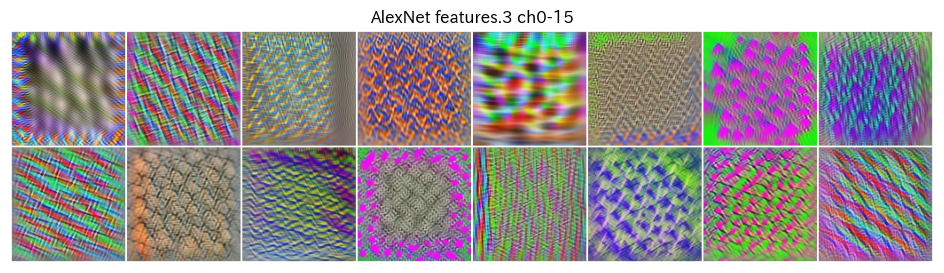

In [ ]:
"""活性最大化 (activation maximization / feature visualization) の試作.

ノイズに近い初期画像から出発し, 指定した層・チャンネルの活性が最大になるよう入力画像を勾配上昇で最適化する.
素朴に画素を直接最適化すると高周波ノイズ (敵対的パターン) になるため, Olah et al. (2017) で
有効とされた 2 つの工夫を入れている:
  1. 画像をフーリエ空間でパラメータ化し, 低周波ほど大きく動くようスケールする (周波数の前処理)
  2. 毎ステップ, ランダムな平行移動・拡大縮小・回転を施してから順伝播する (変換に対する頑健性)
"""
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
from torchvision import models

MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


class FourierImage(nn.Module):
    """フーリエ係数で表した画像. 出力は [0,1] の RGB 画像 [N,3,size,size]"""
    def __init__(self, n, size, decay=1.0, init_std=0.01):
        super().__init__()
        fy = torch.fft.fftfreq(size).view(-1, 1)
        fx = torch.fft.rfftfreq(size).view(1, -1)
        freq = torch.sqrt(fx ** 2 + fy ** 2).clamp(min=1.0 / size)
        self.register_buffer('scale', (1.0 / freq ** decay) / size)    # 1/f スケール
        self.size = size
        self.coef = nn.Parameter(init_std * torch.randn(n, 3, size, size // 2 + 1, 2))

    def forward(self):
        spec = torch.view_as_complex(self.coef) * self.scale
        img = torch.fft.irfft2(spec, s=(self.size, self.size), norm='ortho')
        return torch.sigmoid(img * 4.0)                # 値域を (0,1) に収める


def random_transform(x, jitter=8, scales=(0.95, 1.05), degrees=5):
    """平行移動・拡大縮小・回転をバッチ全体に一括で施す"""
    n = x.shape[0]
    x = F.pad(x, (jitter,) * 4, mode='reflect')
    dx, dy = torch.randint(-jitter, jitter + 1, (2,))
    x = torch.roll(x, shifts=(int(dy), int(dx)), dims=(2, 3))
    s = torch.empty(1).uniform_(*scales)
    a = torch.deg2rad(torch.empty(1).uniform_(-degrees, degrees))
    theta = torch.tensor([[torch.cos(a) / s, -torch.sin(a) / s, 0.],
                          [torch.sin(a) / s,  torch.cos(a) / s, 0.]]).unsqueeze(0).expand(n, 2, 3)
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    x = F.grid_sample(x, grid, padding_mode='reflection', align_corners=False)
    return x[:, :, jitter:-jitter, jitter:-jitter]


class _RedirectedReLUFn(torch.autograd.Function):
    """順伝播は普通の ReLU. 逆伝播では, 入力が負でも「活性を上げる方向」の勾配なら通す.
    初期画像で目標チャンネルが全面的に負 (= 勾配 0) の場合に最適化を立ち上げるための仕掛け."""
    @staticmethod
    def forward(ctx, x):
        ctx.save_for_backward(x)
        return x.clamp(min=0)

    @staticmethod
    def backward(ctx, g):
        x, = ctx.saved_tensors
        # 損失 = -活性 なので, g < 0 は「この値を増やすと損失が下がる」方向
        return g * ((x > 0) | (g < 0)).to(g.dtype)


class RedirectedReLU(nn.Module):
    def forward(self, x):
        return _RedirectedReLUFn.apply(x)


def _swap_relu(model, redirect):
    """model 内の nn.ReLU を RedirectedReLU に置き換え, 元に戻すための記録 (親, 名前, 元の ReLU) を返す"""
    swapped = []
    for mod in model.modules():
        for name, child in list(mod.named_children()):
            if redirect and isinstance(child, nn.ReLU):
                setattr(mod, name, RedirectedReLU()); swapped.append((mod, name, child))
    return swapped


def visualize_channels(model, layer, channels, size=128, steps=256, lr=0.05, seed=0, redirect_steps=32):
    """model の layer (named_modules の名前, 例: 'features.3', 'layer3') について,
    channels の各チャンネルの平均活性を最大化する画像を返す. 戻り値: [len(channels),3,size,size] in [0,1]
    redirect_steps: 最初の何ステップだけ ReLU の勾配を迂回させるか (0 で無効)"""
    torch.manual_seed(seed)
    model = model.eval()
    for p in model.parameters():
        p.requires_grad_(False)
    module = dict(model.named_modules())[layer]
    feats = {}
    # 注意: torchvision の AlexNet/VGG 等は ReLU(inplace=True) なので, 出力をそのまま保持すると
    # 直後の ReLU に上書きされ「ReLU 後」の値になってしまう (負の領域で勾配 0 → 最適化が進まない).
    # フックは ReLU より前に呼ばれるので, ここで clone() して ReLU 前の値を保持する.
    hook = module.register_forward_hook(lambda m, i, o: feats.__setitem__('out', o.clone()))

    img = FourierImage(len(channels), size)
    opt = torch.optim.Adam(img.parameters(), lr=lr)
    idx = torch.arange(len(channels))
    ch = torch.as_tensor(channels)
    swapped = _swap_relu(model, redirect_steps > 0)
    try:
        for step in range(steps):
            if step == redirect_steps:                   # 立ち上げ後は通常の ReLU に戻す
                for mod, name, orig in swapped:
                    setattr(mod, name, orig)
                swapped = []
                # Adam の 2 次モーメントが迂回期の大きな勾配を覚えていると, 以後の歩幅が極端に小さくなる.
                # 切り替え時に最適化器を作り直してリセットする.
                opt = torch.optim.Adam(img.parameters(), lr=lr)
            x = random_transform(img())
            model((x - MEAN) / STD)
            act = feats['out'][idx, ch]                  # 画像 i はチャンネル channels[i] を担当
            loss = -act.mean(dim=(1, 2)).sum()           # 特徴マップ全体の平均活性を最大化
            opt.zero_grad()
            loss.backward()
            opt.step()
    finally:
        hook.remove()
        for mod, name, orig in swapped:              # 例外時も元のモデルに戻す
            setattr(mod, name, orig)
    return img().detach()


def show(imgs, title, fn=None, nrow=8):
    grid = torchvision.utils.make_grid(imgs, nrow=nrow, padding=2, pad_value=1.0)
    fig = plt.figure(figsize=(12, 12 * grid.shape[1] / grid.shape[2]))
    plt.axis('off')
    plt.imshow(grid.permute(1, 2, 0).numpy())
    plt.title(title)
    if fn is not None:
        fig.savefig(fn, dpi=90, bbox_inches='tight')
    plt.show()


if __name__ == '__main__':
    alex = models.alexnet(weights='DEFAULT')
    for layer in ['features.3', 'features.8', 'features.10']:      # conv2, conv4, conv5 (ReLU 前)
        show(visualize_channels(alex, layer, list(range(16))), f'AlexNet {layer} ch0-15', f'fv_alex_{layer}.png')

    res = models.resnet18(weights='DEFAULT')
    for layer in ['layer2', 'layer3', 'layer4']:                    # 各ステージの出力 (ReLU 後)
        show(visualize_channels(res, layer, list(range(16))), f'ResNet18 {layer} ch0-15', f'fv_res_{layer}.png')
